In [1]:
from pathlib import Path
import sys

import joblib
import wandb
import yaml

PROJECT_ROOT = Path(
    r"C:\Users\elsae\Downloads\ecommerce-purchase-prediction"
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import (
    load_raw_data,
    validate_manifest,
    get_split,
)

In [2]:
from pathlib import Path
import sys

import joblib
import wandb
import yaml

PROJECT_ROOT = Path(
    r"C:\Users\elsae\Downloads\ecommerce-purchase-prediction"
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import (
    load_raw_data,
    validate_manifest,
    get_split,
)

In [3]:
# Membaca keputusan model dan threshold yang sudah ditetapkan.
selection_path = PROJECT_ROOT / "configs" / "final_selection.yaml"

with selection_path.open("r", encoding="utf-8") as file:
    final_selection = yaml.safe_load(file)

# Membaca konfigurasi dari run training model terpilih.
source_run = wandb.Api().run(
    final_selection["source_run_path"]
)
source_config = source_run.config

df, manifest = load_raw_data(source_config["data"])
validate_manifest(df, manifest)

# Mengambil sesi test untuk dijelaskan prediksinya.
X_explain, y_explain = get_split(
    df,
    manifest,
    split_name="test",
    target_column=source_config["data"]["target"],
    exclude_columns=source_config["features"]["exclude_columns"],
)

# Memuat pipeline yang sama dengan evaluasi akhir.
pipeline_path = (
    PROJECT_ROOT
    / source_config["output_dir"]
    / source_run.id
    / "pipeline.joblib"
)

pipeline = joblib.load(pipeline_path)

print("Model:", source_run.name)
print("Threshold:", final_selection["threshold"])
print("Data untuk interpretasi:", X_explain.shape)

Model: xgb_all_features
Threshold: 0.3
Data untuk interpretasi: (2470, 17)


In [5]:
# Mengambil preprocessing dan model dari pipeline tersimpan.
preprocessor = pipeline.named_steps["preprocessor"]
model = pipeline.named_steps["model"]

# Mengubah data menggunakan preprocessing hasil training.
X_encoded = preprocessor.transform(X_explain)

# Mengambil nama fitur setelah preprocessing.
feature_names = preprocessor.get_feature_names_out()

print("Sebelum preprocessing:", X_explain.shape)
print("Setelah preprocessing:", X_encoded.shape)
print("Jumlah nama fitur:", len(feature_names))

Sebelum preprocessing: (2470, 17)
Setelah preprocessing: (2470, 73)
Jumlah nama fitur: 73


In [6]:
import numpy as np
import xgboost as xgb

# Menggunakan hasil preprocessing yang sama dengan input model.
dmatrix = xgb.DMatrix(
    X_encoded,
    feature_names=feature_names.tolist(),
)

booster = model.get_booster()

# Menghitung kontribusi SHAP setiap fitur.
shap_contributions = booster.predict(
    dmatrix,
    pred_contribs=True,
    approx_contribs=False,
)

# Kolom terakhir adalah nilai dasar, bukan fitur.
shap_values = shap_contributions[:, :-1]
base_values = shap_contributions[:, -1]

# Memeriksa bahwa kontribusi menjumlah ke skor mentah model.
raw_scores = booster.predict(dmatrix, output_margin=True)

assert np.allclose(
    base_values + shap_values.sum(axis=1),
    raw_scores,
    rtol=1e-5,
    atol=1e-5,
), "Jumlah kontribusi SHAP tidak sesuai dengan skor model."

# Memeriksa kesesuaian prediksi dengan pipeline lengkap.
assert np.allclose(
    booster.predict(dmatrix),
    pipeline.predict_proba(X_explain)[:, 1],
    rtol=1e-5,
    atol=1e-6,
), "Prediksi berbeda dari pipeline asli."

print("Ukuran kontribusi lengkap:", shap_contributions.shape)
print("Ukuran nilai SHAP:", shap_values.shape)
print("Ukuran nilai dasar:", base_values.shape)
print("Pemeriksaan konsistensi berhasil.")

Ukuran kontribusi lengkap: (2470, 74)
Ukuran nilai SHAP: (2470, 73)
Ukuran nilai dasar: (2470,)
Pemeriksaan konsistensi berhasil.


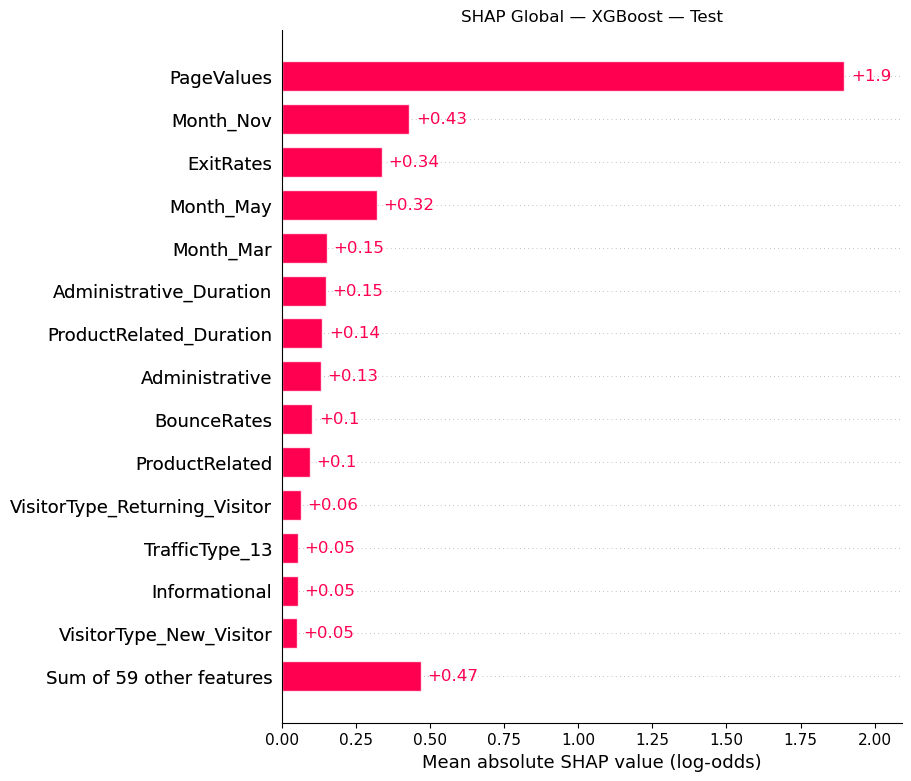

Grafik disimpan: C:\Users\elsae\Downloads\ecommerce-purchase-prediction\outputs\shap\u1b7ipvz\shap_global_bar.png


In [7]:
import shap
import matplotlib.pyplot as plt

# Menyiapkan nilai fitur untuk tampilan grafik.
if hasattr(X_encoded, "toarray"):
    encoded_display = X_encoded.toarray()
else:
    encoded_display = np.asarray(X_encoded)

# Merapikan nama fitur untuk tampilan saja.
plot_feature_names = [
    name.split("__", 1)[-1]
    for name in feature_names
]

shap_explanation = shap.Explanation(
    values=shap_values,
    base_values=base_values,
    data=encoded_display,
    feature_names=plot_feature_names,
)

shap.plots.bar(
    shap_explanation,
    max_display=15,
    show=False,
)

fig = plt.gcf()
fig.axes[0].set_title("SHAP Global — XGBoost — Test")
fig.axes[0].set_xlabel("Mean absolute SHAP value (log-odds)")

# Menyimpan grafik di laptop.
shap_output_dir = PROJECT_ROOT / "outputs" / "shap" / source_run.id
shap_output_dir.mkdir(parents=True, exist_ok=True)

global_bar_path = shap_output_dir / "shap_global_bar.png"
fig.savefig(global_bar_path, dpi=150, bbox_inches="tight")

plt.show()

print("Grafik disimpan:", global_bar_path)

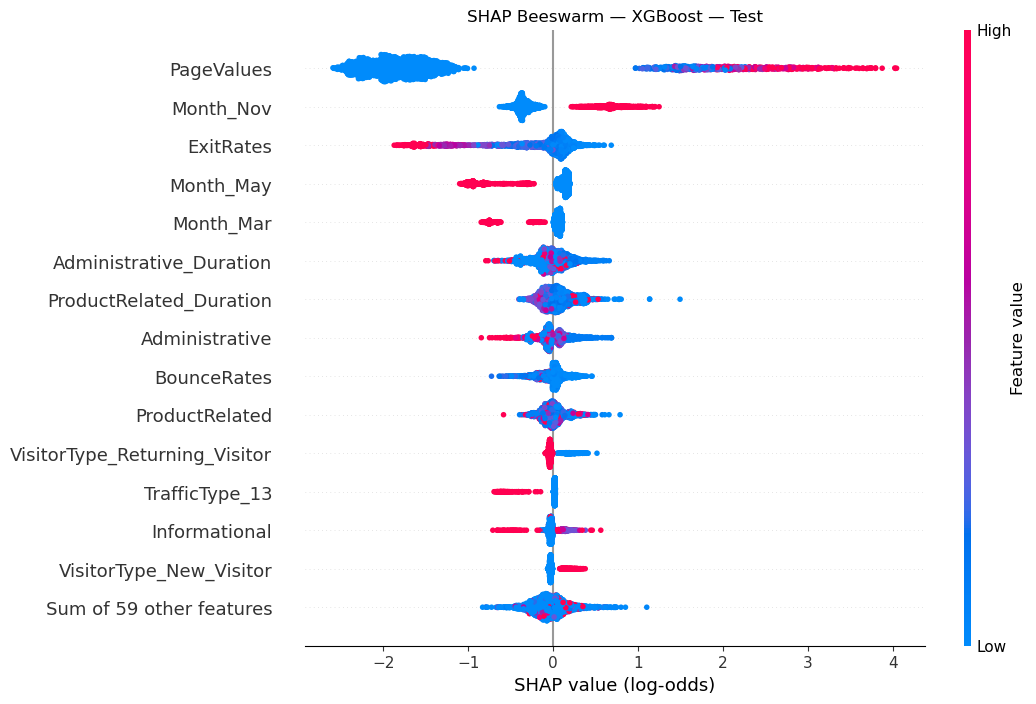

Grafik disimpan: C:\Users\elsae\Downloads\ecommerce-purchase-prediction\outputs\shap\u1b7ipvz\shap_beeswarm.png


In [8]:
plt.figure()

shap.plots.beeswarm(
    shap_explanation,
    max_display=15,
    plot_size=(10, 8),
    show=False,
)

beeswarm_fig = plt.gcf()
beeswarm_fig.axes[0].set_title(
    "SHAP Beeswarm — XGBoost — Test"
)
beeswarm_fig.axes[0].set_xlabel(
    "SHAP value (log-odds)"
)

beeswarm_path = shap_output_dir / "shap_beeswarm.png"

beeswarm_fig.savefig(
    beeswarm_path,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print("Grafik disimpan:", beeswarm_path)

In [9]:
with wandb.init(
    entity="elsaelisa",
    project="ecommerce-purchase-prediction",
    name="shap_xgb_all_features_test",
    job_type="explain",
    mode="online",
    config={
        "source_run_path": final_selection["source_run_path"],
        "explanation_split": "test",
        "n_sessions": len(X_explain),
        "n_encoded_features": len(feature_names),
        "shap_method": "xgboost_native_pred_contribs",
        "output_scale": "log_odds",
        "approx_contribs": False,
    },
) as run:

    run.log({
        "shap/global_bar": wandb.Image(str(global_bar_path)),
        "shap/beeswarm": wandb.Image(str(beeswarm_path)),
    })

    # Menyimpan ID agar grafik berikutnya bisa masuk ke run ini.
    shap_run_id = run.id

    (shap_output_dir / "wandb_run_id.txt").write_text(
        shap_run_id,
        encoding="utf-8",
    )

    print("Link dokumentasi SHAP:", run.url)

wandb: Currently logged in as: rifayel-126140185 (elsaelisa) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Link dokumentasi SHAP: https://wandb.ai/elsaelisa/ecommerce-purchase-prediction/runs/z8yr5eni


Row ID dataset asli: 1
Probabilitas membeli dari model: 0.38%
Threshold: 0.3
Prediksi: Tidak membeli
Kondisi asli: Tidak membeli


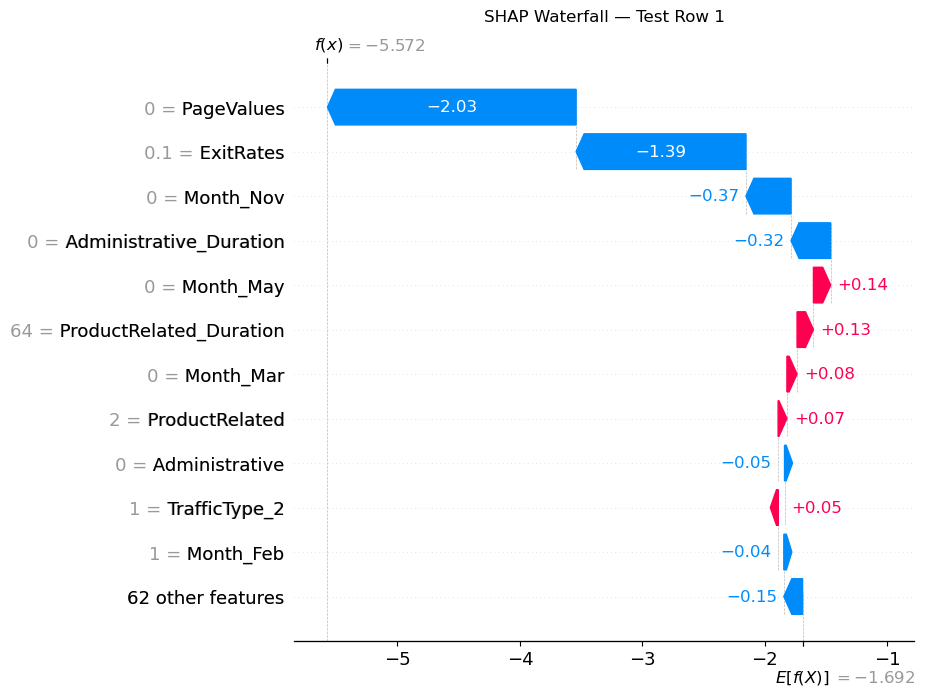

In [10]:
sample_position = 0

sample_row_id = int(X_explain.index[sample_position])
sample_threshold = float(final_selection["threshold"])

sample_probability = float(
    pipeline.predict_proba(
        X_explain.iloc[[sample_position]]
    )[0, 1]
)

sample_prediction = int(
    sample_probability >= sample_threshold
)
sample_actual = int(y_explain.iloc[sample_position])

print("Row ID dataset asli:", sample_row_id)
print("Probabilitas membeli dari model:", f"{sample_probability:.2%}")
print("Threshold:", sample_threshold)
print("Prediksi:", "Membeli" if sample_prediction else "Tidak membeli")
print("Kondisi asli:", "Membeli" if sample_actual else "Tidak membeli")

shap.plots.waterfall(
    shap_explanation[sample_position],
    max_display=12,
    show=False,
)

waterfall_fig = plt.gcf()
waterfall_fig.axes[0].set_title(
    f"SHAP Waterfall — Test Row {sample_row_id}",
    pad=30,
)

waterfall_path = (
    shap_output_dir
    / f"shap_waterfall_row_{sample_row_id}.png"
)

waterfall_fig.savefig(
    waterfall_path,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

In [11]:
shap_run_id = (
    shap_output_dir / "wandb_run_id.txt"
).read_text(encoding="utf-8").strip()

with wandb.init(
    entity="elsaelisa",
    project="ecommerce-purchase-prediction",
    id=shap_run_id,
    resume="must",
    mode="online",
) as run:

    run.log({
        "shap/waterfall_first_test_session": wandb.Image(
            str(waterfall_path)
        )
    })

    run.summary["example/row_id"] = sample_row_id
    run.summary["example/probability"] = sample_probability
    run.summary["example/threshold"] = sample_threshold
    run.summary["example/prediction"] = sample_prediction
    run.summary["example/actual"] = sample_actual

    print("Link dokumentasi:", run.url)

Link dokumentasi: https://wandb.ai/elsaelisa/ecommerce-purchase-prediction/runs/z8yr5eni


example/actual,0
example/prediction,0
example/probability,0.00379
example/row_id,1
example/threshold,0.3


In [12]:
summary_path = PROJECT_ROOT / "docs" / "project_summary.md"

shap_run_id = (
    shap_output_dir / "wandb_run_id.txt"
).read_text(encoding="utf-8").strip()

with wandb.init(
    entity="elsaelisa",
    project="ecommerce-purchase-prediction",
    id=shap_run_id,
    resume="must",
    mode="online",
) as run:

    artifact = wandb.Artifact(
        name="project-summary",
        type="report",
    )

    artifact.add_file(str(summary_path))
    run.log_artifact(artifact)

    print("Ringkasan proyek dikirim:", run.url)

Ringkasan proyek dikirim: https://wandb.ai/elsaelisa/ecommerce-purchase-prediction/runs/z8yr5eni


example/actual,0
example/prediction,0
example/probability,0.00379
example/row_id,1
example/threshold,0.3


In [13]:
from importlib.metadata import version
import sys

packages = [
    "numpy",
    "pandas",
    "scikit-learn",
    "imbalanced-learn",
    "xgboost",
    "wandb",
    "protobuf",
    "PyYAML",
    "joblib",
    "matplotlib",
    "shap",
    "streamlit",
    "ipykernel",
]

requirements_text = "\n".join(
    f"{package}=={version(package)}"
    for package in packages
) + "\n"

requirements_path = PROJECT_ROOT / "requirements.txt"

requirements_path.write_text(
    requirements_text,
    encoding="utf-8",
)

print("Python:", sys.version.split()[0])
print("File disimpan:", requirements_path)
print()
print(requirements_text)

Python: 3.10.14
File disimpan: C:\Users\elsae\Downloads\ecommerce-purchase-prediction\requirements.txt

numpy==2.2.5
pandas==2.2.3
scikit-learn==1.7.1
imbalanced-learn==0.14.2
xgboost==3.2.0
wandb==0.23.0
protobuf==6.32.1
PyYAML==6.0.3
joblib==1.5.3
matplotlib==3.10.7
shap==0.49.1
streamlit==1.50.0
ipykernel==6.30.1



In [14]:
# Membaca pilihan model yang digunakan aplikasi.
selection_path = PROJECT_ROOT / "configs" / "final_selection.yaml"

with selection_path.open("r", encoding="utf-8") as file:
    demo_selection = yaml.safe_load(file)

demo_model_id = demo_selection["source_run_path"].rsplit("/", 1)[-1]

# Struktur folder dipertahankan di dalam artifact.
demo_files = [
    "app.py",
    "README.md",
    "requirements.txt",
    "configs/final_selection.yaml",
    "docs/project_summary.md",
    f"outputs/{demo_model_id}/pipeline.joblib",
]

missing_files = [
    name
    for name in demo_files
    if not (PROJECT_ROOT / name).is_file()
]

if missing_files:
    raise FileNotFoundError(
        "File belum ditemukan: " + ", ".join(missing_files)
    )

with wandb.init(
    entity="elsaelisa",
    project="ecommerce-purchase-prediction",
    name="streamlit_demo_snapshot",
    job_type="app_validation",
    mode="online",
    config={
        "source_run_path": demo_selection["source_run_path"],
        "threshold": float(demo_selection["threshold"]),
        "python_version": sys.version.split()[0],
        "deployment_mode": "local_streamlit",
        "verification_method": "manual_reference_case",
        "reference_case_row_id": 1,
    },
) as run:

    artifact = wandb.Artifact(
        name="ecommerce-streamlit-demo",
        type="application",
    )

    for relative_path in demo_files:
        artifact.add_file(
            str(PROJECT_ROOT / relative_path),
            name=relative_path,
        )

    run.log_artifact(artifact)

    # Berdasarkan hasil pengecekan yang sudah kamu konfirmasi.
    run.summary["reference_case/manual_passed"] = True
    run.summary["reference_case/expected_display_percent"] = 0.38

    print("Paket demo dikirim:", run.url)

Paket demo dikirim: https://wandb.ai/elsaelisa/ecommerce-purchase-prediction/runs/peipachd


reference_case/expected_display_percent,0.38
reference_case/manual_passed,True
